# Phase Results: Multiclass Emotion Classification

**Project:** Music emotion classification  
**Target:** `Emotion_Label` (angry, calm, energetic, happy, romantic, sad)  
**Dataset:** `data/raw_dataset.csv`

we designed this notebook to produce a reproducible comparison, tuning records, uncertainty estimates, error analysis, sensitivity/robustness experiments, and files for the Results Package.

## 1. Experimental protocol

- Fixed split: 64% train, 16% validation, 20% test; stratified; seed 42.
- Primary metric: macro-F1, because each emotion class should contribute equally.
- Secondary metrics: accuracy, balanced accuracy, macro precision, macro recall, weighted F1.
- Preprocessing: median imputation + standardization for numeric features; most-frequent imputation + one-hot encoding for categorical features. All preprocessing is fitted inside each model pipeline, using training folds only.
- Tuning: randomized search on training data with stratified 5-fold CV; final model choice is checked on validation data.
- Final repeatability: repeat selected configurations over multiple seeds where the estimator supports stochastic training. Keep the data split fixed.

In [20]:
import os, sys, json, random, platform, subprocess, warnings, time
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV,
    cross_validate, learning_curve
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score,
    recall_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
from scipy.stats import randint, loguniform

warnings.filterwarnings("ignore")

SEED = 42
SEEDS_FINAL = [42, 123, 456, 789, 2026]
N_SPLITS = 5
N_ITER = 30
TARGET = "Emotion_Label"
DATA_FILE = "raw_dataset.csv"
DROP_COLS = ["Track_ID"]

random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
REPORTS_DIR = ROOT / "reports" / "phase_results"
FIG_DIR = REPORTS_DIR / "figures"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Root:", ROOT)
print("Python:", sys.version.split()[0], "| sklearn:", sklearn.__version__)

Root: c:\Users\juse7\Code Creations VI\Machine-Learning\machine-learning-course-project
Python: 3.13.9 | sklearn: 1.7.2


## 2. Environment and run metadata

In [21]:
def git_commit(root):
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "--short", "HEAD"],
            cwd=root, stderr=subprocess.DEVNULL
        ).decode().strip()
    except Exception:
        return "n/a"

env_info = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "seed": SEED,
    "final_seeds": SEEDS_FINAL,
    "cv_folds": N_SPLITS,
    "tuning_trials_per_model": N_ITER,
    "git_commit": git_commit(ROOT),
    "split_protocol": "64/16/20; stratified; random_state=42",
    "test_set_previously_evaluated_in_prior_stage": True
}
(REPORTS_DIR / "run_metadata.json").write_text(json.dumps(env_info, indent=2))
print(json.dumps(env_info, indent=2))

{
  "timestamp": "2026-11-20T19:57:20",
  "python": "3.13.9",
  "platform": "Windows-11-10.0.26300-SP0",
  "numpy": "2.4.4",
  "pandas": "3.0.0",
  "scikit-learn": "1.7.2",
  "seed": 42,
  "final_seeds": [
    42,
    123,
    456,
    789,
    2026
  ],
  "cv_folds": 5,
  "tuning_trials_per_model": 30,
  "git_commit": "ba88237",
  "split_protocol": "64/16/20; stratified; random_state=42",
  "test_set_previously_evaluated_in_prior_stage": true
}


## 3. Dataset Pipeline

In [22]:
DATA_PATH = DATA_DIR / DATA_FILE
df = pd.read_csv(DATA_PATH)

print("Data source:", DATA_PATH)
print("Raw shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

missing_drop_cols = [c for c in DROP_COLS if c in df.columns]
df = df.drop(columns=missing_drop_cols)
n_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().dropna(subset=[TARGET]).reset_index(drop=True)

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].astype(str).copy()
class_names = sorted(y.unique().tolist())
K = len(class_names)

quality = pd.DataFrame({
    "dtype": X.dtypes.astype(str),
    "missing_count": X.isna().sum(),
    "missing_percent": (X.isna().mean() * 100).round(2),
    "unique_values": X.nunique()
})
display(quality)
display(y.value_counts().rename("count").to_frame().assign(
    share=(y.value_counts(normalize=True).round(4))
))
print(f"Duplicates removed: {n_duplicates}")
print(f"Rows after cleaning: {len(df)} | features: {X.shape[1]} | classes: {K}")

Data source: c:\Users\juse7\Code Creations VI\Machine-Learning\machine-learning-course-project\data\raw_dataset.csv
Raw shape: (5000, 10)


,Track_ID,Genre,Tempo,Energy,Danceability,Loudness,Acousticness,Instrumentalness,Valence,Emotion_Label
0,T00001,classical,112.44,0.394,0.374,-30.02,0.730,0.092,0.638,happy
1,T00002,blues,193.10,0.473,0.333,-15.20,0.185,0.061,0.459,sad
2,T00003,hiphop,162.48,0.855,0.176,-26.24,0.347,0.604,0.964,calm
3,T00004,disco,143.81,0.340,0.607,-55.00,0.663,0.966,0.219,romantic
4,T00005,disco,81.84,0.870,0.477,-48.87,0.482,0.503,0.588,angry


Columns: ['Track_ID', 'Genre', 'Tempo', 'Energy', 'Danceability', 'Loudness', 'Acousticness', 'Instrumentalness', 'Valence', 'Emotion_Label']


,dtype,missing_count,missing_percent,unique_values
Genre,str,0,0.0,10
Tempo,float64,0,0.0,4251
Energy,float64,0,0.0,996
Danceability,float64,0,0.0,997
Loudness,float64,0,0.0,3355
Acousticness,float64,0,0.0,991
Instrumentalness,float64,0,0.0,993
Valence,float64,0,0.0,997


,count,share
Emotion_Label,,
romantic,866,0.1732
calm,864,0.1728
angry,832,0.1664
happy,822,0.1644
energetic,816,0.1632
sad,800,0.1600


Duplicates removed: 0
Rows after cleaning: 5000 | features: 8 | classes: 6


## 4. Shared preprocessing and evaluation

In [23]:
# Fixed Split
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.20, stratify=y_trainval, random_state=SEED)

split_summary = pd.DataFrame({
    "n_rows": [len(X_train), len(X_val), len(X_test)],
    "share": [len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
}, index=["train", "validation", "test"]).round(4)
display(split_summary)

class_share = pd.concat({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}, axis=1).round(4).loc[class_names]
display(class_share)

pd.DataFrame({
    "row_index": np.concatenate([X_train.index, X_val.index, X_test.index]),
    "partition": (["train"] * len(X_train)) + (["validation"] * len(X_val)) + (["test"] * len(X_test)),
}).to_csv(REPORTS_DIR / "split_indices.csv", index=False)

# Pre-processing
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]
print("Numeric features: ", numeric_cols)
print("Categorical features: ", categorical_cols)

def make_preprocessor(numeric=None, categorical=None, scale_numeric=True):
    numeric = numeric_cols if numeric is None else numeric
    categorical = categorical_cols if categorical is None else categorical

    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))

    transformers = []
    if numeric:
        transformers.append(("num", Pipeline(num_steps), numeric))
    if categorical:
        transformers.append(("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical))
    return ColumnTransformer(transformers, remainder="drop")

def make_pipeline(estimator, **prep_kwargs):
    return Pipeline([("prep", make_preprocessor(**prep_kwargs)), ("model", estimator)])

# Metrics
LABELS = class_names

def metric_dict(y_true, y_pred):
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", labels=LABELS, zero_division=0),
    }

SCORING = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_precision": "precision_macro",
    "macro_recall": "recall_macro",
    "weighted_f1": "f1_weighted",
}
REFIT_METRIC = "macro_f1"

# Shared CV Folds
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

def cv_evaluate(name, estimator, X_tr=None, y_tr=None):
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    t0 = time.time()
    res = cross_validate(
        estimator, X_tr, y_tr, cv=cv, scoring=SCORING,
        return_train_score=True, n_jobs=-1, error_score="raise",
    )
    row = {"model": name}
    for m in SCORING:
        row[f"cv_{m}_mean"] = res[f"test_{m}"].mean()
        row[f"cv_{m}_std"] = res[f"test_{m}"].std(ddof=1)
    row["cv_train_macro_f1_mean"] = res["train_macro_f1"].mean()
    row["fit_seconds_mean"] = res["fit_time"].mean()
    row["cv_seconds_total"] = time.time() - t0
    return row

# Fit on training data
def evaluate_split(name, estimator, X_tr, y_tr, X_ev, y_ev, partition="validation"):
    t0 = time.time()
    estimator.fit(X_tr, y_tr)
    fit_s = time.time() - t0
    y_pred = estimator.predict(X_ev)
    row = {"model": name, "partition": partition, **metric_dict(y_ev, y_pred), "fit_seconds": fit_s}
    return row, y_pred

# Sanity Check
_check_row, _ = evaluate_split(
    "dummy_most_frequent",
    make_pipeline(DummyClassifier(strategy="most_frequent")),
    X_train, y_train, X_val, y_val,
)
display(pd.DataFrame([_check_row]).round(4))

,n_rows,share
train,3200,0.64
validation,800,0.16
test,1000,0.20


,train,validation,test
Emotion_Label,,,
angry,0.1666,0.1662,0.166
calm,0.1728,0.1725,0.173
energetic,0.1631,0.1638,0.163
happy,0.1644,0.1638,0.165
romantic,0.1731,0.1737,0.173
sad,0.1600,0.1600,0.160


Numeric features:  ['Tempo', 'Energy', 'Danceability', 'Loudness', 'Acousticness', 'Instrumentalness', 'Valence']
Categorical features:  ['Genre']


,model,partition,macro_f1,accuracy,balanced_accuracy,macro_precision,macro_recall,weighted_f1,fit_seconds
0,dummy_most_frequent,validation,0.0493,0.1737,0.1667,0.029,0.1667,0.0514,0.0077


## 5. Baselines and candidate models

The two naive classifiers and the two linear baselines from the previous stage are kept as reference points, with the exact settings used there. Phase 4 found that linear models barely beat random guessing (test macro-F1 0.174 vs a 0.165 random floor), so the new candidates are all **non-linear** models that can capture interactions between features:

| Model | Group | Why it is included |
|---|---|---|
| Naive (majority class) | Naive | Always predicts the most common emotion; the lowest possible reference point |
| Naive (stratified random) | Naive | Guesses at random in proportion to class frequencies; the "random floor" (about 1/6 for six balanced classes) |
| Logistic Regression | Linear (Phase 4) | Phase 4 baseline, same settings (`C=1.0`, `max_iter=2000`) |
| Linear SVM | Linear (Phase 4) | Phase 4 baseline, same settings (`C=1.0`, `max_iter=20000`) |
| RBF SVM | Non-linear (kernel) | Kernel version of the SVM; draws curved decision boundaries |
| Random Forest | Non-linear (trees) | Averages many decision trees; captures feature interactions |
| Extra Trees | Non-linear (trees) | Like Random Forest but with randomized splits; often less variance |
| HistGradientBoosting | Non-linear (boosting) | Builds trees one after another, each correcting the last; usually the strongest tabular model |

The class-weighted ("balanced") variants from Phase 4 are dropped: the classes are already near-balanced (16.0–17.3%), and weighting lowered validation macro-F1 there.

New candidates start at library defaults. Tuning happens in Section 7. Every model is wrapped in the same `make_pipeline()` preprocessing from Section 4, so score differences come from the model, not the data handling.

This cell also sets up the **experiment log** (`reports/phase_results/experiment_log.csv`, Part B of the submission). Every run from here on adds one row, so each number in the Results section can be traced back to a run ID.

In [24]:
from sklearn.base import clone

# ---- Candidate models ---------------------------------------------------------
# Baselines use the exact Phase 4 settings; new candidates use library defaults.
# Tree models get n_jobs=1 because cross_validate already runs the CV folds in parallel.
CANDIDATES = {
    "Naive (majority class)":    DummyClassifier(strategy="most_frequent"),
    "Naive (stratified random)": DummyClassifier(strategy="stratified", random_state=SEED),
    "Logistic Regression":       LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    "Linear SVM":                LinearSVC(C=1.0, dual="auto", max_iter=20000, random_state=SEED),
    "RBF SVM":                   SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED),
    "Random Forest":             RandomForestClassifier(random_state=SEED, n_jobs=1),
    "Extra Trees":               ExtraTreesClassifier(random_state=SEED, n_jobs=1),
    "HistGradientBoosting":      HistGradientBoostingClassifier(random_state=SEED),
}
MODEL_GROUP = {
    "Naive (majority class)": "Naive",
    "Naive (stratified random)": "Naive",
    "Logistic Regression": "Linear (Phase 4)",
    "Linear SVM": "Linear (Phase 4)",
    "RBF SVM": "Non-linear (kernel)",
    "Random Forest": "Non-linear (trees)",
    "Extra Trees": "Non-linear (trees)",
    "HistGradientBoosting": "Non-linear (boosting)",
}

def describe(estimator):
    """One-line description of an estimator, showing only settings changed from the defaults."""
    return " ".join(repr(estimator).split())

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(
        [{"model": n, "group": MODEL_GROUP[n], "settings": describe(e)} for n, e in CANDIDATES.items()]
    ).set_index("model"))

# ---- Experiment log (Part B of the submission) --------------------------------
LOG_PATH = REPORTS_DIR / "experiment_log.csv"
LOG_COLUMNS = ["run_id", "date", "section", "model", "hyperparameters", "seed",
               "data_split", "val_score", "test_score", "runtime_s", "observations"]
SPLIT_DESC = "64/16/20 stratified (seed 42); 5-fold stratified CV on train"

def log_runs(rows):
    """Add rows to the experiment log. Re-running a section replaces its rows (same run_id) instead of duplicating them."""
    new = pd.DataFrame(rows, columns=LOG_COLUMNS)
    if LOG_PATH.exists():
        old = pd.read_csv(LOG_PATH)
        new = pd.concat([old[~old["run_id"].isin(new["run_id"])], new], ignore_index=True)
    new = new.sort_values("run_id").reset_index(drop=True)
    new.to_csv(LOG_PATH, index=False)
    return new

print(f"{len(CANDIDATES)} models defined. Experiment log: {LOG_PATH.relative_to(ROOT)}")

,group,settings
model,,
Naive (majority class),Naive,DummyClassifier(strategy='most_frequent')
Naive (stratified random),Naive,"DummyClassifier(random_state=42, strategy='stratified')"
Logistic Regression,Linear (Phase 4),"LogisticRegression(max_iter=2000, random_state=42)"
Linear SVM,Linear (Phase 4),"LinearSVC(max_iter=20000, random_state=42)"
RBF SVM,Non-linear (kernel),SVC(random_state=42)
Random Forest,Non-linear (trees),"RandomForestClassifier(n_jobs=1, random_state=42)"
Extra Trees,Non-linear (trees),"ExtraTreesClassifier(n_jobs=1, random_state=42)"
HistGradientBoosting,Non-linear (boosting),HistGradientBoostingClassifier(random_state=42)


8 models defined. Experiment log: reports\phase_results\experiment_log.csv


## 6. Initial comparable evaluation

Every candidate goes through exactly the same procedure:

1. **5-fold stratified CV on the training partition**, using the same `cv` folds object for every model.
2. **Fit on the full training partition and score once on validation.**

The test set is not used here. We use these scores to decide which models to tune and investigate further.

**How to read the table**
- `cv_macro_f1_mean` / `cv_macro_f1_std`: mean and standard deviation of macro-F1 across the 5 CV folds.
- `cv_train_macro_f1_mean`: macro-F1 on the data the model was trained on. A large gap above the CV score means the model is memorizing rather than generalizing.
- `val_macro_f1`: score on the held-out validation partition.
- `gap_vs_random`: CV macro-F1 minus the random floor. Random guessing in proportion to class frequencies has an expected macro-F1 of 1/K = 1/6 ≈ 0.167.

**Outputs:** `reports/phase_results/initial_comparison.csv` (all metrics) and experiment-log rows `S06-01` … `S06-08`.

In [25]:
RANDOM_FLOOR = 1 / K   # expected macro-F1 of stratified random guessing

initial_rows, log_rows, val_preds = [], [], {}
for i, (name, est) in enumerate(CANDIDATES.items(), start=1):
    # (1) 5-fold CV on the training partition: same folds for every model
    cv_row = cv_evaluate(name, make_pipeline(clone(est)))
    # (2) fit on the full training partition, score once on validation
    val_row, val_preds[name] = evaluate_split(
        name, make_pipeline(clone(est)), X_train, y_train, X_val, y_val)

    row = {"run_id": f"S06-{i:02d}", "group": MODEL_GROUP[name], **cv_row}
    row.update({f"val_{m}": val_row[m] for m in SCORING})
    row["val_fit_seconds"] = val_row["fit_seconds"]
    initial_rows.append(row)

    log_rows.append({
        "run_id": row["run_id"],
        "date": datetime.now().strftime("%Y-%m-%d"),
        "section": "6. Initial comparison",
        "model": name,
        "hyperparameters": describe(est),
        "seed": SEED,
        "data_split": SPLIT_DESC,
        "val_score": round(val_row["macro_f1"], 4),
        "test_score": np.nan,   # test set not used in this section
        "runtime_s": round(cv_row["cv_seconds_total"] + val_row["fit_seconds"], 2),
        "observations": (f"Default settings, initial screening. "
                         f"CV macro-F1 {cv_row['cv_macro_f1_mean']:.4f} +/- {cv_row['cv_macro_f1_std']:.4f}; "
                         f"train macro-F1 {cv_row['cv_train_macro_f1_mean']:.4f}."),
    })

initial = (pd.DataFrame(initial_rows)
           .sort_values("cv_macro_f1_mean", ascending=False)
           .reset_index(drop=True))
initial["gap_vs_random"] = initial["cv_macro_f1_mean"] - RANDOM_FLOOR
initial.to_csv(REPORTS_DIR / "initial_comparison.csv", index=False)
log_runs(log_rows)

display(initial[[
    "run_id", "model", "group", "cv_macro_f1_mean", "cv_macro_f1_std",
    "cv_train_macro_f1_mean", "val_macro_f1", "val_accuracy", "gap_vs_random", "val_fit_seconds",
]].round(4))
print(f"Random floor (1/K): {RANDOM_FLOOR:.4f}")
print(f"Saved: {(REPORTS_DIR / 'initial_comparison.csv').relative_to(ROOT)} and {len(log_rows)} log rows")

,run_id,model,group,cv_macro_f1_mean,cv_macro_f1_std,cv_train_macro_f1_mean,val_macro_f1,val_accuracy,gap_vs_random,val_fit_seconds
0,S06-08,HistGradientBoosting,Non-linear (boosting),0.1706,0.0152,1.0000,0.1689,0.1688,0.0039,1.3543
1,S06-06,Random Forest,Non-linear (trees),0.1684,0.0055,1.0000,0.1609,0.1612,0.0017,0.5546
2,S06-04,Linear SVM,Linear (Phase 4),0.1645,0.0106,0.2080,0.1579,0.1625,-0.0022,0.0127
3,S06-03,Logistic Regression,Linear (Phase 4),0.1644,0.0121,0.2089,0.1603,0.1650,-0.0023,0.0586
4,S06-05,RBF SVM,Non-linear (kernel),0.1622,0.0102,0.3884,0.1670,0.1675,-0.0045,0.2771
5,S06-02,Naive (stratified random),Naive,0.1597,0.0228,0.1704,0.1635,0.1638,-0.0070,0.0094
6,S06-07,Extra Trees,Non-linear (trees),0.1577,0.0097,1.0000,0.1684,0.1700,-0.0090,0.2759
7,S06-01,Naive (majority class),Naive,0.0490,0.0002,0.0492,0.0493,0.1737,-0.1176,0.0079


Random floor (1/K): 0.1667
Saved: reports\phase_results\initial_comparison.csv and 8 log rows


### What the initial comparison shows

- **Phase 4 is reproduced exactly.** Logistic Regression (S06-03) gets CV 0.1644 / validation 0.1603, and Linear SVM (S06-04) gets CV 0.1645 / validation 0.1579, the same values as the Phase 4 notebook. So the split, preprocessing and metric are unchanged, and the comparison with the new models is like-for-like.
- **No model clearly beats random guessing.** Every non-naive model lands between 0.158 and 0.171 CV macro-F1, within about 0.01 of the 1/6 ≈ 0.167 random floor. The best, HistGradientBoosting (S06-08, 0.1706 ± 0.0152), is only 0.004 above the floor, far less than its own fold-to-fold standard deviation.
- **The tree models memorize the training data.** Random Forest, Extra Trees and HistGradientBoosting all reach training macro-F1 = 1.000 but only about 0.16–0.17 in CV. At default settings they fit noise rather than a pattern that generalizes, so tuning should focus on constraining them (tree depth, leaf size, learning rate).
- **Non-linear models do not clearly beat linear ones.** This is consistent with the Phase 4 hypothesis that the features carry little information about the emotion label. It is not conclusive yet: it needs tuning (Section 7) and uncertainty estimates (Section 10) before it can be reported as a finding.

**Decision:** all six non-naive models go forward to tuning. The differences between them are too small to rule any out at this stage.

## 7. Hyperparameter tuning

Using randomized search with same number of sampled configurations per model if possible.

All search is performed on `X_train` using CV. Validation is kept for a separate comparison after tuning.

Each model receives N_ITER sampled configurations. Macro-F1 is the refit metric; all preprocessing is part of the pipeline and is re-fitted within each CV fold.

In [26]:
from sklearn.model_selection import ParameterSampler

# Tune each non-naive model using only X_train/y_train and the shared CV folds.
# The preprocessing remains inside the pipeline, preventing fold leakage.
TUNING_SPACES = {
    "Logistic Regression": {
        "model__C": loguniform(1e-3, 1e2),
        "model__solver": ["lbfgs"],
    },
    "Linear SVM": {
        "model__C": loguniform(1e-3, 1e2),
    },
    "RBF SVM": {
        "model__C": loguniform(1e-2, 1e2),
        "model__gamma": loguniform(1e-4, 1e1),
    },
    "Random Forest": {
        "model__n_estimators": randint(300, 801),
        "model__max_depth": [3, 4, 5, 6, 8, 10],
        "model__min_samples_split": randint(10, 61),
        "model__min_samples_leaf": randint(5, 41),
        "model__max_features": ["sqrt", "log2", 0.3, 0.5],
        "model__ccp_alpha": loguniform(1e-5, 1e-1),
        "model__bootstrap": [True]
    },
    "Extra Trees": {
        "model__n_estimators": randint(200, 601),
        "model__max_depth": [None, 5, 10, 20, 30],
        "model__min_samples_split": randint(2, 21),
        "model__min_samples_leaf": randint(1, 11),
        "model__max_features": ["sqrt", "log2", 0.5, None],
    },
    "HistGradientBoosting": {
        "model__learning_rate": loguniform(0.005, 0.15),
        "model__max_iter": randint(50, 301),
        "model__max_leaf_nodes": randint(3, 16),
        "model__max_depth": [2, 3, 4, 5],
        "model__min_samples_leaf": randint(20, 101),
        "model__l2_regularization": loguniform(0.01, 100),
        "model__max_features": [0.5, 0.7, 0.9, 1.0],
    },
}

TUNED_MODELS = list(TUNING_SPACES)
tuning_rows, tuning_log_rows, tuned_estimators = [], [], {}

for i, name in enumerate(TUNED_MODELS, start=1):
    print(f"Tuning {name} ({i}/{len(TUNED_MODELS)})...")
    search = RandomizedSearchCV(
        estimator=make_pipeline(clone(CANDIDATES[name])),
        param_distributions=TUNING_SPACES[name],
        n_iter=N_ITER,
        scoring=SCORING,
        refit=REFIT_METRIC,
        cv=cv,
        random_state=SEED,
        n_jobs=-1,
        return_train_score=True,
        error_score="raise",
        verbose=0,
    )
    t0 = time.time()
    search.fit(X_train, y_train)
    elapsed = time.time() - t0
    tuned_estimators[name] = search.best_estimator_

    best_idx = search.best_index_
    row = {
        "run_id": f"S07-{i:02d}",
        "model": name,
        "best_cv_macro_f1": search.best_score_,
        "best_cv_macro_f1_std": search.cv_results_["std_test_macro_f1"][best_idx],
        "best_cv_train_macro_f1": search.cv_results_["mean_train_macro_f1"][best_idx],
        "n_iter": N_ITER,
        "search_seconds": elapsed,
        "best_params": json.dumps(search.best_params_, default=str, sort_keys=True),
    }
    tuning_rows.append(row)
    tuning_log_rows.append({
        "run_id": row["run_id"],
        "date": datetime.now().strftime("%Y-%m-%d"),
        "section": "7. Hyperparameter tuning",
        "model": name,
        "hyperparameters": row["best_params"],
        "seed": SEED,
        "data_split": SPLIT_DESC,
        "val_score": np.nan,
        "test_score": np.nan,
        "runtime_s": round(elapsed, 2),
        "observations": (
            f"RandomizedSearchCV; {N_ITER} configurations; "
            f"best training-CV macro-F1={search.best_score_:.4f}."
        ),
    })

tuning_results = (pd.DataFrame(tuning_rows)
                  .sort_values("best_cv_macro_f1", ascending=False)
                  .reset_index(drop=True))
tuning_results.to_csv(REPORTS_DIR / "tuning_results.csv", index=False)
log_runs(tuning_log_rows)
display(tuning_results.drop(columns="best_params").round(4))
print("Saved:", REPORTS_DIR / "tuning_results.csv")

Tuning Logistic Regression (1/6)...
Tuning Linear SVM (2/6)...
Tuning RBF SVM (3/6)...
Tuning Random Forest (4/6)...
Tuning Extra Trees (5/6)...
Tuning HistGradientBoosting (6/6)...


,run_id,model,best_cv_macro_f1,best_cv_macro_f1_std,best_cv_train_macro_f1,n_iter,search_seconds
0,S07-06,HistGradientBoosting,0.1770,0.0064,0.4252,30,6.9622
1,S07-04,Random Forest,0.1698,0.0082,0.8630,30,14.7930
2,S07-01,Logistic Regression,0.1666,0.0097,0.2102,30,0.6976
3,S07-05,Extra Trees,0.1659,0.0136,0.9884,30,6.9100
4,S07-02,Linear SVM,0.1645,0.0095,0.2079,30,0.6626
5,S07-03,RBF SVM,0.1586,0.0162,1.0000,30,6.2301


Saved: c:\Users\juse7\Code Creations VI\Machine-Learning\machine-learning-course-project\reports\phase_results\tuning_results.csv


## 8. Comparing configurations on validation data

Kept the original linear baselines and naive benchmarks in the comparison. Added tuned estimators.

The three highest-scoring non-naive configurations on validation are carried forward.

In [27]:
# Compare the tuned models against the original baselines on validation.
validation_rows, validation_log_rows, validation_predictions = [], [], {}

comparison_estimators = {
    name: make_pipeline(clone(est))
    for name, est in CANDIDATES.items()
}
comparison_estimators.update(tuned_estimators)

for i, (name, estimator) in enumerate(comparison_estimators.items(), start=1):
    row, pred = evaluate_split(
        name, estimator, X_train, y_train, X_val, y_val, partition="validation"
    )
    validation_predictions[name] = pred
    validation_rows.append({
        "run_id": f"S08-{i:02d}",
        "model": name,
        "group": MODEL_GROUP.get(name, "Tuned"),
        **{f"val_{k}": v for k, v in row.items()
           if k in SCORING},
        "val_fit_seconds": row["fit_seconds"],
    })
    validation_log_rows.append({
        "run_id": f"S08-{i:02d}",
        "date": datetime.now().strftime("%Y-%m-%d"),
        "section": "8. Validation comparison",
        "model": name,
        "hyperparameters": describe(estimator),
        "seed": SEED,
        "data_split": SPLIT_DESC,
        "val_score": round(row["macro_f1"], 4),
        "test_score": np.nan,
        "runtime_s": round(row["fit_seconds"], 2),
        "observations": "Fit on training partition; evaluated on validation only.",
    })

validation_comparison = (pd.DataFrame(validation_rows)
                         .sort_values("val_macro_f1", ascending=False)
                         .reset_index(drop=True))
validation_comparison.to_csv(REPORTS_DIR / "validation_comparison.csv", index=False)
log_runs(validation_log_rows)
display(validation_comparison.round(4))

# Carry the three strongest non-naive validation performers to final test evaluation.
non_naive_validation = validation_comparison[
    ~validation_comparison["model"].str.startswith("Naive")
].copy()
FINALISTS = non_naive_validation.head(3)["model"].tolist()
print("Finalists selected using validation macro-F1:", FINALISTS)
print("Saved:", REPORTS_DIR / "validation_comparison.csv")

,run_id,model,group,val_macro_f1,val_accuracy,val_balanced_accuracy,val_macro_precision,val_macro_recall,val_weighted_f1,val_fit_seconds
0,S08-05,RBF SVM,Non-linear (kernel),0.1774,0.1812,0.1800,0.1781,0.1800,0.1782,0.3140
1,S08-08,HistGradientBoosting,Non-linear (boosting),0.1766,0.1788,0.1783,0.1763,0.1783,0.1768,0.9254
2,S08-06,Random Forest,Non-linear (trees),0.1733,0.1762,0.1752,0.1737,0.1752,0.1740,1.8381
3,S08-02,Naive (stratified random),Naive,0.1635,0.1638,0.1635,0.1637,0.1635,0.1636,0.0084
4,S08-03,Logistic Regression,Linear (Phase 4),0.1586,0.1638,0.1633,0.1602,0.1633,0.1588,0.0190
5,S08-04,Linear SVM,Linear (Phase 4),0.1579,0.1625,0.1623,0.1592,0.1623,0.1581,0.0118
6,S08-07,Extra Trees,Non-linear (trees),0.1495,0.1500,0.1497,0.1502,0.1497,0.1496,0.5595
7,S08-01,Naive (majority class),Naive,0.0493,0.1737,0.1667,0.0290,0.1667,0.0514,0.0093


Finalists selected using validation macro-F1: ['RBF SVM', 'HistGradientBoosting', 'Random Forest']
Saved: c:\Users\juse7\Code Creations VI\Machine-Learning\machine-learning-course-project\reports\phase_results\validation_comparison.csv


## 9. Final test evaluation

Each finalist is re-fitted on the combined training and validation partitions, then evaluated once on the untouched test partition

In [28]:
# Final evaluation: refit the validation-selected finalists on train + validation,
# then evaluate each exactly once on the held-out test partition.
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

test_rows, test_log_rows, test_predictions = [], [], {}
for i, name in enumerate(FINALISTS, start=1):
    if name in tuned_estimators:
        estimator = clone(tuned_estimators[name])
    else:
        estimator = make_pipeline(clone(CANDIDATES[name]))

    test_row, pred = evaluate_split(
        name, estimator, X_trainval, y_trainval, X_test, y_test,
        partition="test"
    )
    test_predictions[name] = pred
    test_rows.append({
        "run_id": f"S09-{i:02d}",
        "model": name,
        **{k: v for k, v in test_row.items() if k in SCORING},
        "fit_seconds": test_row["fit_seconds"],
    })
    test_log_rows.append({
        "run_id": f"S09-{i:02d}",
        "date": datetime.now().strftime("%Y-%m-%d"),
        "section": "9. Final test evaluation",
        "model": name,
        "hyperparameters": describe(estimator),
        "seed": SEED,
        "data_split": "64/16/20 stratified; final fit on train + validation",
        "val_score": np.nan,
        "test_score": round(test_row["macro_f1"], 4),
        "runtime_s": round(test_row["fit_seconds"], 2),
        "observations": "Final held-out test evaluation; model selected before test access.",
    })

final_test_results = (pd.DataFrame(test_rows)
                      .sort_values("macro_f1", ascending=False)
                      .reset_index(drop=True))
final_test_results.to_csv(REPORTS_DIR / "final_test_results.csv", index=False)
log_runs(test_log_rows)

pred_frame = pd.DataFrame({"y_true": y_test.to_numpy()})
for name, pred in test_predictions.items():
    pred_frame[f"pred_{name}"] = np.asarray(pred)
pred_frame.to_csv(REPORTS_DIR / "final_test_predictions.csv", index=False)

display(final_test_results.round(4))
print("Saved:", REPORTS_DIR / "final_test_results.csv")
print("Saved:", REPORTS_DIR / "final_test_predictions.csv")

,run_id,model,macro_f1,accuracy,balanced_accuracy,macro_precision,macro_recall,weighted_f1,fit_seconds
0,S09-03,Random Forest,0.1765,0.179,0.1780,0.1764,0.1780,0.1773,2.1725
1,S09-01,RBF SVM,0.1748,0.177,0.1760,0.1758,0.1760,0.1754,0.4731
2,S09-02,HistGradientBoosting,0.1708,0.172,0.1717,0.1709,0.1717,0.1711,0.9471


Saved: c:\Users\juse7\Code Creations VI\Machine-Learning\machine-learning-course-project\reports\phase_results\final_test_results.csv
Saved: c:\Users\juse7\Code Creations VI\Machine-Learning\machine-learning-course-project\reports\phase_results\final_test_predictions.csv


## 10. Uncertainty: bootstrap confidence intervals

bootstrap confidence interval over test observations for each finalist's pooled predictions. This estimates test-sample uncertainty conditional on a fitted model.


In [29]:
N_BOOTSTRAP = 5000
BOOTSTRAP_SEED = 42

def bootstrap_macro_f1(
    y_true,
    y_pred,
    n_bootstrap=5000,
    random_state=42
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    rng = np.random.default_rng(random_state)

    scores = []

    for _ in range(n_bootstrap):

        indices = rng.choice(
            len(y_true),
            size=len(y_true),
            replace=True
        )

        score = f1_score(
            y_true[indices],
            y_pred[indices],
            labels=class_names,
            average="macro",
            zero_division=0
        )

        scores.append(score)

    scores = np.asarray(scores)

    return {
        "bootstrap_mean": scores.mean(),
        "ci_lower": np.percentile(scores, 2.5),
        "ci_upper": np.percentile(scores, 97.5),
        "bootstrap_std": scores.std(ddof=1),
        "scores": scores
    }


In [30]:

predictions_df = pd.read_csv(
    REPORTS_DIR / "final_test_predictions.csv"
)

model_columns = {
    "HistGradientBoosting": "pred_HistGradientBoosting",
    "Random Forest": "pred_Random Forest",
    "RBF SVM": "pred_RBF SVM"
}

bootstrap_results = []
bootstrap_distributions = {}

for i, (model_name, pred_col) in enumerate(
    model_columns.items()
):

    result = bootstrap_macro_f1(
        predictions_df["y_true"],
        predictions_df[pred_col],
        n_bootstrap=N_BOOTSTRAP,
        random_state=BOOTSTRAP_SEED + i
    )

    bootstrap_distributions[model_name] = result["scores"]

    bootstrap_results.append({
        "model": model_name,
        "test_macro_f1": f1_score(
            predictions_df["y_true"],
            predictions_df[pred_col],
            labels=class_names,
            average="macro"
        ),
        "bootstrap_mean": result["bootstrap_mean"],
        "ci_lower": result["ci_lower"],
        "ci_upper": result["ci_upper"],
        "bootstrap_std": result["bootstrap_std"]
    })

bootstrap_results = pd.DataFrame(bootstrap_results)

bootstrap_results.to_csv(
    REPORTS_DIR / "bootstrap_confidence_intervals.csv",
    index=False
)

display(bootstrap_results.round(4))


,model,test_macro_f1,bootstrap_mean,ci_lower,ci_upper,bootstrap_std
0,HistGradientBoosting,0.1708,0.1704,0.1477,0.1946,0.0120
1,Random Forest,0.1765,0.1761,0.1533,0.2003,0.0120
2,RBF SVM,0.1748,0.1742,0.1509,0.1980,0.0121


## 11. Main-results figure

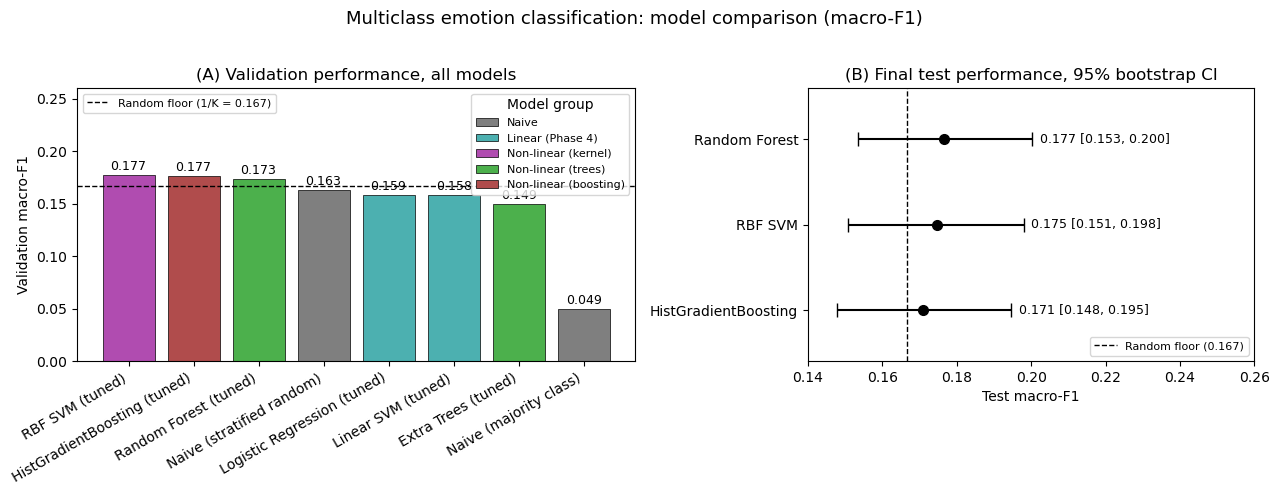

,model,val_macro_f1,test_macro_f1,ci_lower,ci_upper,ci_includes_random_floor
0,Random Forest,0.1733,0.1765,0.1533,0.2003,True
1,RBF SVM,0.1774,0.1748,0.1509,0.1980,True
2,HistGradientBoosting,0.1766,0.1708,0.1477,0.1946,True


Saved: reports\phase_results\figures\main_results.png
Saved: reports\phase_results\main_results_table.csv


In [ ]:
GROUP_COLORS = {
    "Naive": "#7f7f7f",
    "Linear (Phase 4)": "#4cb0b0",
    "Non-linear (kernel)": "#b04cb0",
    "Non-linear (trees)": "#4cb04c",
    "Non-linear (boosting)": "#b04c4c",
}

# Figure A: validation macro-F1 for every model
val_plot = validation_comparison.sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
val_labels = [f"{m} (tuned)" if m in TUNED_MODELS else m for m in val_plot["model"]]
val_colors = [GROUP_COLORS[g] for g in val_plot["group"]]

# Figure B: test macro-F1 with 95% bootstrap CIs
test_plot = bootstrap_results.sort_values("test_macro_f1", ascending=True).reset_index(drop=True)
point = test_plot["test_macro_f1"].to_numpy()
lower = point - test_plot["ci_lower"].to_numpy()
upper = test_plot["ci_upper"].to_numpy() - point
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.25, 1]})

# Figure A
ax1.bar(val_labels, val_plot["val_macro_f1"], color=val_colors, edgecolor="black", linewidth=0.5)
for i, v in enumerate(val_plot["val_macro_f1"]):
    ax1.text(i, v + 0.002, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
ax1.axhline(RANDOM_FLOOR, color="black", linestyle="--", linewidth=1, label=f"Random floor (1/K = {RANDOM_FLOOR:.3f})")
ax1.set_ylim(0, 0.26)
ax1.set_ylabel("Validation macro-F1")
ax1.set_xticks(range(len(val_labels)))
ax1.set_xticklabels(val_labels, rotation=30, ha="right")
ax1.set_title("(A) Validation performance, all models")

group_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=c, edgecolor="black", linewidth=0.5) for c in GROUP_COLORS.values()]
group_legend = ax1.legend(group_handles, list(GROUP_COLORS), title="Model group", loc="upper right", fontsize=8)
ax1.add_artist(group_legend)
ax1.legend(loc="upper left", fontsize=8)

# Figure B
ypos = np.arange(len(test_plot))
ax2.errorbar(point, ypos, xerr=[lower, upper], fmt="o", color="black", capsize=5, markersize=7, linewidth=1.5)
for i, row in test_plot.iterrows():
    ax2.text(row["ci_upper"] + 0.002, i, f"{row['test_macro_f1']:.3f} [{row['ci_lower']:.3f}, {row['ci_upper']:.3f}]", va="center", fontsize=9)
ax2.axvline(RANDOM_FLOOR, color="black", linestyle="--", linewidth=1, label=f"Random floor ({RANDOM_FLOOR:.3f})")
ax2.set_yticks(ypos)
ax2.set_yticklabels(test_plot["model"])
ax2.set_ylim(-0.6, len(test_plot) - 0.4)
ax2.set_xlim(0.14, 0.26)
ax2.set_xlabel("Test macro-F1")
ax2.set_title("(B) Final test performance, 95% bootstrap CI")
ax2.legend(loc="lower right", fontsize=8)

fig.suptitle("Multiclass emotion classification: model comparison (macro-F1)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIG_DIR / "main_results.png", dpi=300, bbox_inches="tight")
plt.show()

main_results_table = bootstrap_results.merge(validation_comparison[["model", "val_macro_f1"]], on="model", how="left")
main_results_table["ci_includes_random_floor"] = ((main_results_table["ci_lower"] <= RANDOM_FLOOR) & (RANDOM_FLOOR <= main_results_table["ci_upper"]))
main_results_table = (main_results_table[["model", "val_macro_f1", "test_macro_f1", "ci_lower", "ci_upper", "ci_includes_random_floor"]]
                        .sort_values("test_macro_f1", ascending=False)
                        .reset_index(drop=True))
main_results_table.to_csv(REPORTS_DIR / "main_results_table.csv", index=False)
display(main_results_table.round(4))

print("Saved:", (FIG_DIR / "main_results.png").relative_to(ROOT))
print("Saved:", (REPORTS_DIR / "main_results_table.csv").relative_to(ROOT))

## 12. Error analysis



### Confusion matrices

## 13. Sensitivity analysis



## 14. Robustness analysis



## 15. Ablation study



## 16. Limitations
